

# Pipelined ADCs & Datasheet Forensics: Inside the MS9280 and AD9280

**Course:** Digital Design 
**Topic:** Pipelined ADC Architecture, Stage-by-Stage Math, and Real-World Engineering Specs  

### Learning Objectives
By the end of this module, you will be able to:
1. Explain what a **Sample-and-Hold Amplifier (SHA)** is and why every pipeline stage needs one.
2. Contrast **Flash**, **SAR ("interval halving")**, and **Pipeline** ADCs in terms of hardware cost, latency, and throughput.
3. Trace a voltage through one pipeline stage: **Sub-ADC $\rightarrow$ Sub-DAC $\rightarrow$ Subtraction & Magnification**.
4. Explain **how many bits are achieved per stage** in the MS9280's **`2.5 – 2.5 – 2.5 – 2.5 – 2`** pipeline.
5. Use **Datasheet Forensics** (SNR, ENOB, and spec comparison) to spot an IC clone and recognize why the MS9280's last 2 bits are bogus.

---

## 1. Hardware Context: Two Chips, One Architecture

In this course, we are studying the **MS9280** (Hangzhou Ruimeng Technology), a low-cost, pin-compatible clone of the classic Analog Devices **AD9280**. Both are fast, low-power **pipelined ADCs** used in software-defined radio, video capture, and FPGA data acquisition.

| Datasheet Claim | Analog Devices AD9280 | Ruimeng MS9280 |
| :--- | :--- | :--- |
| **Output Pins** | **8 bits** (`D7`–`D0`) | **10 bits** (`D9`–`D0`) |
| **Max Sample Rate** | 32 MSPS | 35 MSPS |
| **Pipeline Latency** | 3 clock cycles | 3 clock cycles |
| **Typical SNR / SINAD** | **49 dB** | **49 dB** (47.8 / 46.5 dB min) |
| **Effective Bits (ENOB)** | **7.7 – 7.8 bits** | **7.7 – 7.8 bits** *(listed in its own spec table!)* |

*(Wait—why does a "10-bit" chip list **7.8 effective bits**? Keep reading—we will prove why in Section 7!)*

---

## 2. First Things First: What Is a SHA?

Before any ADC can convert a signal, it faces one big problem: **the input voltage is constantly moving.**

If an input sine wave changes while our comparators are making decisions, the top bits and bottom bits will measure two different voltages and produce garbage.

A **Sample-and-Hold Amplifier (SHA)** acts like a **camera shutter** for voltage:
1. **Sample mode:** An internal switch closes and charges a tiny capacitor to match the incoming voltage.
2. **Hold mode:** The switch snaps open. A buffer holds that capacitor's voltage **completely flat and steady** while the stage measures it.

```text
                Sample Mode (Switch Closed)      Hold Mode (Switch Open)
  V_in (moving) ────o/ o────┬───► Buffer         ────o /o────┬───► Flat, steady
                            │                                │     V_held for
                           ═╪═ C_hold                       ═╪═    measurement
                            ▼                                ▼
```

**Why is there a SHA inside *every* pipeline stage?**  
In digital circuits, you put **D flip-flops** between pipeline stages so Stage 1 can work on new data while Stage 2 works on old data. A **SHA** is the **analog equivalent of a D flip-flop**—it freezes a voltage snapshot for each stage so all stages can work at the same time.

---

## 3. Why Use a Pipeline? (Flash vs. SAR vs. Pipeline)

Suppose you want to turn a voltage into an **8-bit** (0–255) or **10-bit** (0–1,023) number at **35 million samples per second**. You have three ways to build an ADC:

### Option A: Flash ADC ("Brute Force")
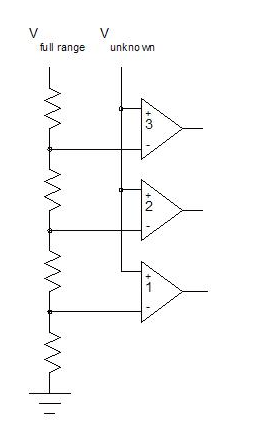
* Compares $V_{\text{in}}$ against **every possible voltage threshold at once**.
* **Pros:** Finishes in **1 clock cycle**.
* **Cons:** Requires $2^N - 1$ comparators. That is **255 comparators** for 8 bits, and **1,023 comparators** for 10 bits—massive chip area and battery drain, and the accuracy of the resistors required is very hard to achieve.

### Option B: SAR ADC ("Interval Halving")
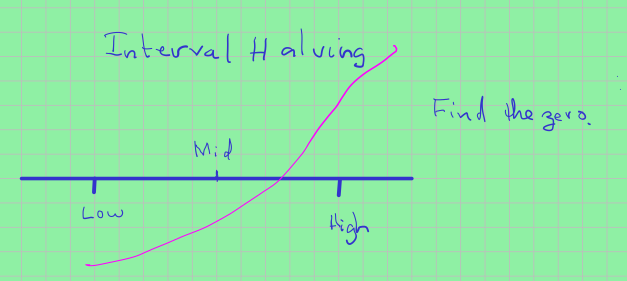
* A **Successive Approximation Register (SAR)** ADC works just like guessing a number between 0 and 255 by **interval halving (binary search)**:
  1. Cycle 1: *"Is it in the top half ($\ge 128$) or bottom half ($< 128$)?"* $\rightarrow$ **Gets 1 bit (MSB).**
  2. Cycle 2: Cut the winning half in half again. $\rightarrow$ **Gets 1 more bit.**
  3. Repeat until you narrow down to 1 step.
* **Pros:** Tiny and low power—uses **1 comparator**.
* **Cons:** It only achieves **1 bit per clock cycle**. A 10-bit conversion takes 10 cycles, so outputting 35 MSPS would require a ~350 MHz internal clock!

#### How could you make a successive approximation ADC?
You repeat the same steps until you have your k bits.  Each time, you magnify the remaining interval by two, so it looks like the original problem, and repeat k times.  There are two ways (see the note below), but the first is how I think the MS9808
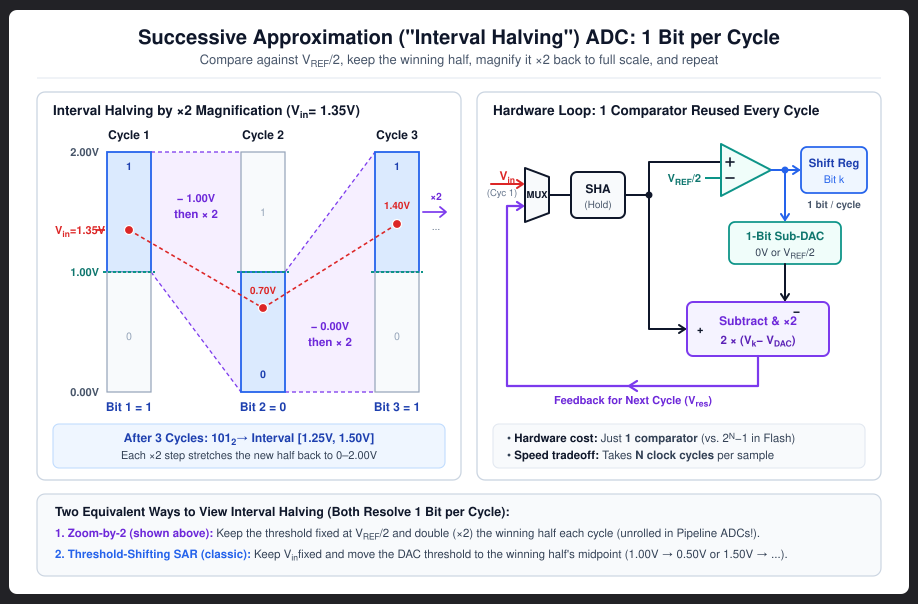

### Option C: Pipeline ADC ("The Assembly Line")
Instead of 1 comparator working 10 cycles in a row (SAR), or 1,023 comparators working all at once (Flash), a **Pipeline ADC** lines up **5 small stages in a row**, separated by SHAs.

| Architecture | Hardware Cost (10-bit) | Bits Resolved per Step | Latency (1 sample) | Throughput (output rate) |
| :--- | :---: | :---: | :---: | :---: |
| **Flash** | 1,023 comparators | All $N$ bits at once | 1 cycle | **1 sample / cycle** |
| **SAR (Interval Halving)** | 1 comparator | **1 bit / cycle** | $N$ cycles | $1/N$ samples / cycle |
| **Pipeline (MS9280)** | ~27 comparators total | **2 net bits / stage** | **3 cycles** | **1 sample / cycle** |

---

## 4. System Block Diagram & Pipeline Timing

On Page 4 of the MS9280 datasheet (matching Page 1 of the AD9280 datasheet), the chip is organized into **4 multiplying stages** plus **1 final Flash stage**:

```text
                    MS9280 System Architecture (Datasheet p. 4)
                    ===========================================

            ┌──────────┐    ┌──────────────────────────────────────────┐
AIN ───────►│ Clamp &  │───►│              PIPELINE CORE               │
(Analog In) │ Input SHA│    │ Stg 1 ─► Stg 2 ─► Stg 3 ─► Stg 4 ─► Final│
            └──────────┘    │ (2.5b)   (2.5b)   (2.5b)   (2.5b)   (2b) │
                            └───┬────────┬────────┬────────┬────────┬──┘
                                │        │        │        │        │
                                ▼        ▼        ▼        ▼        ▼
                            ┌──────────────────────────────────────────┐
CLK ────► Timing &          │    Time-Alignment Shift Registers &      │
          2-Phase Gen       │   Digital Calibration / Correction Logic │
                            └────────────────────┬─────────────────────┘
VREF ───► 1V Reference                           │
          (Int / Ext)                            ▼
                            ┌──────────────────────────────────────────┐
THREE-STATE ───────────────►│         Output Buffers / Latches         │
STBY ───► Power Control     └────────────────────┬─────────────────────┘
                                                 │
                                                 ▼
                                       D9 (MSB) ── D0 (LSB) + OTR
                                      (Note: D1 & D0 are in noise!)
```

### Understanding Throughput vs. Latency
Think of a car wash with 5 stations in a row:
* **Latency:** How long it takes *one* car to travel from entrance to exit.
* **Throughput:** How often a clean car rolls out the exit—once the line is full, **one car exits per beat**.
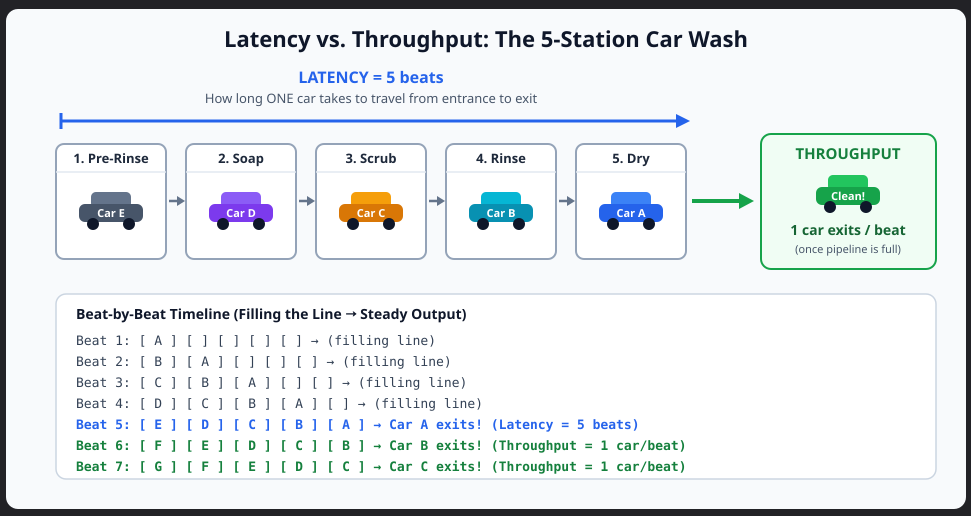

The MS9280 uses **both the rising and falling edges** of `CLK` so two stages finish during each full clock period:
* **Odd stages (Stg 1, Stg 3, Final)** convert on one half-cycle while **Even stages (Stg 2, Stg 4)** sample.
* **Even stages (Stg 2, Stg 4)** convert on the opposite half-cycle while **Odd stages** sample.

| Clock Edge | Sample $S_1$ | Sample $S_2$ | Sample $S_3$ | Sample $S_4$ | Output Pins |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **$T_0$ ($\uparrow$)** | Stg 1 | — | — | — | *(old data)* |
| **$T_0 + 0.5$ ($\downarrow$)** | Stg 2 | — | — | — | *(old data)* |
| **$T_1$ ($\uparrow$)** | Stg 3 | **Stg 1** | — | — | *(old data)* |
| **$T_1 + 0.5$ ($\downarrow$)** | Stg 4 | Stg 2 | — | — | *(old data)* |
| **$T_2$ ($\uparrow$)** | Final + Align | Stg 3 | **Stg 1** | — | *(old data)* |
| **$T_3$ ($\uparrow$)** | **Output Ready!** | Final + Align | Stg 3 | **Stg 1** | **Sample $S_1$** |
| **$T_4$ ($\uparrow$)** | *(done)* | **Output Ready!** | Final + Align | Stg 3 | **Sample $S_2$** |

**Key Result:** Every individual sample takes **3 clock cycles** to emerge (**latency**), but once the pipeline is full, a new finished number pops out on **every rising clock edge** (**throughput**).

---

## 5. Inside a Single Pipeline Stage

Stages 1 through 4 are identical assembly-line stations. Each one measures a rough piece of the voltage, subtracts out what it just measured, and **magnifies** the leftover remainder for the next stage.

```text
                      Inside One Pipeline Stage (Stage k)
                      ===================================

                   ┌─────────┐
  From Previous ──►│   SHA   ├────────────────────────────────┐
  Stage (V_in)     │ (Hold)  │                                │ (+)
                   └────┬────┘                                ▼
                        │                              ┌─────────────┐
                        ▼                              │ Difference  │
                   ┌─────────┐  Coarse    ┌─────────┐  │  Amplifier  ├──► To Next
                   │ Sub-ADC ├─────┬─────►│ Sub-DAC ├─►│  & Gain (G) │    Stage
                   │ (Flash) │     │      └─────────┘  └─────────────┘   (V_res)
                   └─────────┘     │                (-)
                                   ▼
                            To Digital Error
                            Correction Logic
```

Let's zoom into the three key operations inside this stage.

---

### A. How the Stage ADC (Sub-ADC) Works
The **Sub-ADC** is a **mini Flash ADC** that quickly sorts the frozen voltage $V_{\text{held}}$ into a few coarse zones.

For a **2-bit Sub-ADC** on a $0\text{–}2.0\text{ V}$ span, just **3 comparators** divide the input range into 4 equal zones ($0.5\text{ V}$ wide):

```text
  V_held ──┬──►(+) Comparator 3  (Threshold = 1.5 V) ──┐
           ├──►(+) Comparator 2  (Threshold = 1.0 V) ──┼──► 3-to-2 Encoder ──► Coarse Bits
           └──►(+) Comparator 1  (Threshold = 0.5 V) ──┘                        (00, 01, 10, 11)
```

* All 3 comparators fire **at the exact same instant**.
* A small digital encoder converts their outputs into a **2-bit coarse guess** (`00`, `01`, `10`, or `11`) and sends it both to the digital backend and to the stage's Sub-DAC.

---

### B. How the Stage DAC (Sub-DAC) Works
Why put a **DAC** inside an ADC? Because Stage 1 only made a **coarse guess** (e.g., *"The voltage is in Zone `10`, somewhere between $1.0\text{ V}$ and $1.5\text{ V}$"*). To let Stage 2 measure the **leftover fraction** above $1.0\text{ V}$, the stage must recreate an exact $1.0\text{ V}$ analog signal so we can subtract it away.

That is the **Sub-DAC's** job:

1. It takes the coarse binary bits from the Sub-ADC.
2. Those bits act as switches connected to precision reference voltage taps derived from `VREF`.
3. It outputs the exact starting voltage of that zone ($V_{\text{DAC}}$):

| Sub-ADC Guess | Voltage Zone ($0\text{–}2\text{ V}$ Span) | Sub-DAC Output ($V_{\text{DAC}}$) |
| :---: | :---: | :---: |
| `00` | $0.0\text{ V} \le V_{\text{held}} < 0.5\text{ V}$ | **$0.0\text{ V}$** |
| `01` | $0.5\text{ V} \le V_{\text{held}} < 1.0\text{ V}$ | **$0.5\text{ V}$** |
| `10` | $1.0\text{ V} \le V_{\text{held}} < 1.5\text{ V}$ | **$1.0\text{ V}$** |
| `11` | $1.5\text{ V} \le V_{\text{held}} \le 2.0\text{ V}$ | **$1.5\text{ V}$** |

> **Key Rule:** Even though the Sub-ADC only has a handful of zones, the **Sub-DAC's voltage levels must be accurate to the full precision of the entire chip**. Building an ultra-accurate 4-level DAC is much easier than building a 1,024-level Flash ADC!

#### How do you make an accurate 4-level DAC?
First, you need to understand the R-2R network. This is a commonly used network for digital-to-analog converters.
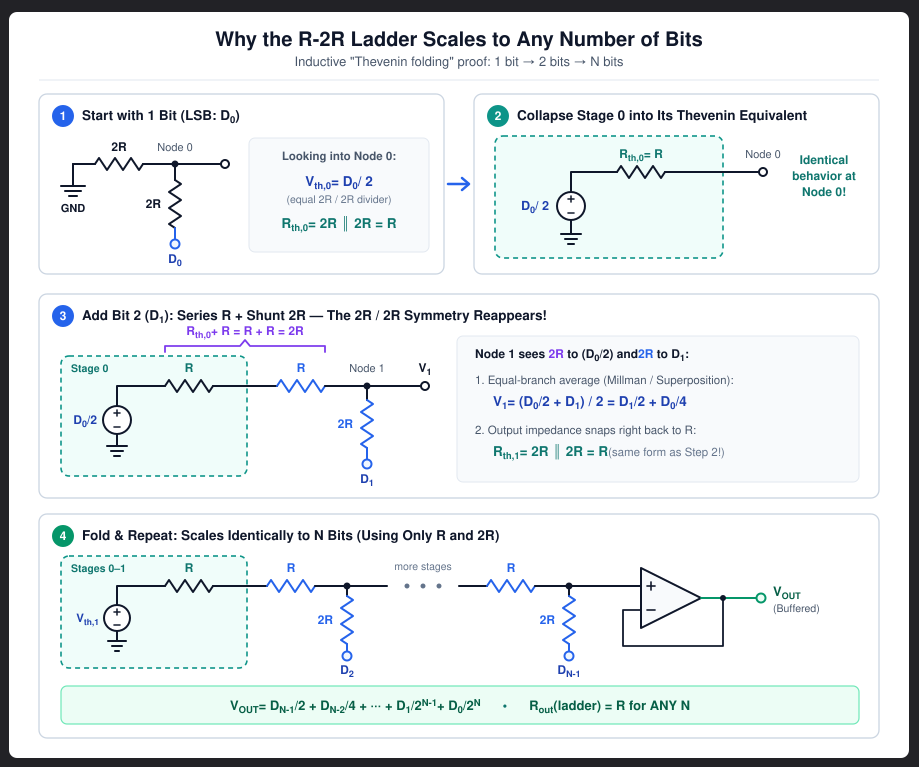
The big advantage of this over something like an inverting summing amplifier is that it uses the same resistor value throughout, because you can make 2R by putting two R resistors in series.  On an IC, it is hard to make an exact resistor value, but you can make two resistors with very similar resistance.

---

### C. How Subtraction and Magnification Work
This block (labeled `SUM` on the MS9280 diagram and `GAIN` on the AD9280 diagram) is the **analog difference amplifier with gain** you already know:

$$V_{\text{residue}} = G \cdot \left(V_{\text{held}} - V_{\text{DAC}}\right)$$

#### Step 1: Subtraction (Isolate the Leftover)
Subtracting the Sub-DAC voltage from $V_{\text{held}}$ strips away the coarse part we already measured:

$$V_{\text{err}} = V_{\text{held}} - V_{\text{DAC}}$$

For a 2-bit stage, this leftover $V_{\text{err}}$ is always a small voltage between **$0\text{ V}$ and $0.5\text{ V}$**.

#### Step 2: Magnification (Stretch Back to Full Scale)
Why not send $V_{\text{err}}$ directly to Stage 2 without magnifying it? Two reasons:
* **Noise Floor:** After 3 or 4 stages, the leftover voltage would shrink to microvolts and get buried in electrical noise.
* **Hardware Reuse:** Stage 2's comparators are built for a $0\text{–}2.0\text{ V}$ range, not a $0\text{–}0.5\text{ V}$ range.

So the amplifier multiplies the difference by **$G = 4$** (for a 2-net-bit stage, since $2^2 = 4$):

$$V_{\text{residue}} = 4 \cdot \left(V_{\text{held}} - V_{\text{DAC}}\right)$$

Multiplying $[0\text{ V}, 0.5\text{ V}]$ by $4$ stretches the leftover right back across the full **$[0\text{ V}, 2.0\text{ V}]$** range! Stage 2 can now use the **exact same circuit** as Stage 1.

---

## 6. How Many Bits Are Achieved Per Stage?

Look closely at the stage labels printed on Page 4 of the MS9280 datasheet: **`2.5` – `2.5` – `2.5` – `2.5` – `2`**.

### Why "2.5 Bits" Instead of "2 Bits"?
* **Net bits achieved per stage:** Stages 1 through 4 each contribute **2 net bits** (and use Gain $G = 4$), and the Final Flash stage resolves **2 bits**:
  $$\underbrace{2}_{\text{Stg 1}} + \underbrace{2}_{\text{Stg 2}} + \underbrace{2}_{\text{Stg 3}} + \underbrace{2}_{\text{Stg 4}} + \underbrace{2}_{\text{Final}} = \mathbf{10\text{ bits}}$$
* **What is the extra ".5 bit"?** In real silicon, comparators aren't perfect—a tiny voltage offset near a boundary could make Stage 1 guess wrong, saturating Stage 2. So each multiplying stage adds **extra comparators (from 3 up to 6 comparators)** to create a **0.5-bit safety overlap** between stages.
* If an analog comparator makes a small mistake, the magnified residue stays safely inside Stage 2's range, and the **Digital Calibration / Correction Logic** (a binary adder + shift registers that time-align the bits arriving at different clock edges) automatically cancels the error!

### Worked Numerical Example ($V_{\text{in}} = 1.370\text{ V}$ on a $0\text{–}2.000\text{ V}$ Span)
Using the clean **2 net bits per stage** ($G = 4$) math:

| Stage | Input ($V_{\text{in},k}$) | Net Bits | $V_{\text{DAC},k}$ | Subtract ($V_{\text{in},k} - V_{\text{DAC},k}$) | Magnify ($\times 4$) $\rightarrow$ Next Stage |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Stage 1** | $1.370\text{ V}$ | **`10`** | $1.000\text{ V}$ | $0.370\text{ V}$ | **$1.480\text{ V}$** |
| **Stage 2** | $1.480\text{ V}$ | **`10`** | $1.000\text{ V}$ | $0.480\text{ V}$ | **$1.920\text{ V}$** |
| **Stage 3** | $1.920\text{ V}$ | **`11`** | $1.500\text{ V}$ | $0.420\text{ V}$ | **$1.680\text{ V}$** |
| **Stage 4** | $1.680\text{ V}$ | **`11`** | $1.500\text{ V}$ | $0.180\text{ V}$ | **$0.720\text{ V}$** |
| **Final Flash** | $0.720\text{ V}$ | **`01`** | *(none)* | — | *(done)* |

* **10-Bit Output:** `10_10_11_11_01`$_2 = 701_{10} \implies \frac{701}{1024} \times 2.000\text{ V} = \mathbf{1.3691\text{ V}}$
* **Top 8 Bits Only:** `10101111`$_2 = 175_{10} \implies \frac{175}{256} \times 2.000\text{ V} = \mathbf{1.3672\text{ V}}$

---

## 7. Datasheet Forensics: Why the MS9280's Last 2 Bits Are Bogus

If the MS9280 draws a 10-bit **`2.5 – 2.5 – 2.5 – 2.5 – 2`** pipeline and puts 10 pins (`D9`–`D0`) on the package, why did we say its last two bits are bogus?

Let's apply the fundamental **ADC Signal-to-Noise Ratio (SNR) Formula**:

$$\text{SNR}_{\text{ideal}} = 6.02\,N + 1.76\text{ dB}$$

Every **1 true bit** of resolution requires **~6 dB** of SNR:
* **Ideal 8-bit ADC:** $6.02(8) + 1.76 = \mathbf{49.9\text{ dB}}$
* **Ideal 10-bit ADC:** $6.02(10) + 1.76 = \mathbf{62.0\text{ dB}}$

Now open **Page 7 of the MS9280 datasheet** and read its own measured specifications:
* **SNR:** `49 dB` typical (`47.8 dB` min)
* **SINAD:** `49 dB` typical (`46.5 dB` min)
* **Effective Bits (ENOB):** **`7.8` typical (`7.7` min)** *(even misprinted with the unit `dB`!)*

Plug `49 dB` into the formula:

$$\text{ENOB} = \frac{49 - 1.76}{6.02} = \mathbf{7.85\text{ bits}} \quad (\text{and } 7.43\text{ bits at } 46.5\text{ dB min})$$

### How Did This Happen? (Comparing the AD9280 and MS9280 PDFs)
Comparing the Analog Devices **AD9280** datasheet and the Ruimeng **MS9280** datasheet side by side exposes the full story:
1. **Identical Legacy Specs:** Both chips share identical oddly specific numbers—`31.7 mA` supply current, `95 mW` power, `43 µA` leakage, `4 ns` aperture delay, `2 ps` jitter, `300 MHz` bandwidth, `49 dB` SNR, and `7.7–7.8` ENOB. Even the MS9280 schematics still list Analog Devices support chips (`REF43`, `AD8041`, `AD876-8`).
2. **Where the Extra 2 Pins Came From:** Analog Devices originally designed the 8-bit AD9280 and the 10-bit AD9200 in the same 28-pin package (`DNC` on pins 3–4 for AD9280; `D0–D1` on pins 3–4 for AD9200—ADI even left `D0–D9` as a typo on Figure 33 of the AD9280 datasheet!).
3. **Why the Bottom 2 Bits Fail:** You cannot get 10-bit performance just by adding 2 pins or extra backend resolution if your **front-end analog noise** (thermal noise in the Input SHA and Stage 1, plus clock jitter) already sits at **$-49\text{ dB}$** (~1/256 of full scale). Anything below Bit 7 is drowning in random noise—meaning **`D1` and `D0` are just digitizing noise**, and real-world FPGA designs routinely discard them.

> **Engineering Takeaway:** Always check **SNR, SINAD, and ENOB** in the electrical tables—never trust the bit count printed on Page 1!

---

## 8. Digital Interface Quick Reference (For FPGA / Lab Use)

* **`CLK`:** Drives the two-phase pipeline; use a clean ~50% duty-cycle clock.
* **`D9–D0` (or `D7–D0`):** Straight binary output latched on every rising edge of `CLK`—representing the analog input sampled **3 clock cycles earlier**.
* **`OTR` (Out-of-Range):** Goes `HIGH` if `AIN` exceeds the voltage reference limits:
  * `OTR = 1, MSB = 1` $\rightarrow$ **Overflow** (input too high)
  * `OTR = 1, MSB = 0` $\rightarrow$ **Underflow** (input too low)
* **`THREE-STATE`:** Pull `HIGH` to float the output pins (`Hi-Z`) for bus sharing.
* **`STBY`:** Pull `HIGH` to put the analog core to sleep (~4 mW).

---

## 9. Review & Discussion Questions

1. **SHA Concept:** Why must every pipeline stage have its own SHA instead of only having one SHA at the chip's front entrance?  
   *(Answer: Each stage needs a frozen voltage snapshot so Stage 1 can work on a new sample while Stages 2–4 work on previous samples simultaneously.)*
2. **SAR vs. Pipeline:** A SAR ADC uses "interval halving" to achieve 1 bit per cycle. How many **net** bits does each multiplying stage of the MS9280 achieve, and why is each labeled `2.5` on the block diagram?  
   *(Answer: 2 net bits per stage with Gain = 4; the extra `0.5` bit represents overlapping comparators that let digital correction fix small comparator errors.)*
3. **Stage Math:** A 2-net-bit stage ($0\text{–}2\text{ V}$ range, $G=4$) receives $V_{\text{in}} = 0.85\text{ V}$. Find its Sub-ADC bits, $V_{\text{DAC}}$, and the magnified residue passed to the next stage.  
   *(Answer: Zone $[0.5, 1.0) \Rightarrow$ Bits = `01`, $V_{\text{DAC}} = 0.50\text{ V}$, $V_{\text{residue}} = 4 \times (0.85 - 0.50) = 1.40\text{ V}$.)*
4. **Datasheet Forensics:** A chip claims "12-bit resolution" on Page 1, but Page 7 lists `SINAD = 56 dB`. Using $\text{ENOB} = (\text{SINAD} - 1.76) / 6.02$, how many true bits are you actually getting?  
   *(Answer: $(56 - 1.76) / 6.02 \approx \mathbf{9.0\text{ bits}}$—the bottom 3 bits are buried in noise and distortion!)*